# Linear Regression Analysis of Systolic Blood Pressure

*Regression and Time Series Models – Group project (Group 3)*

**Goal.** Estimate a linear regression model for systolic arterial pressure and check whether the classical assumptions hold, with particular attention to **homoskedasticity**. Heteroskedasticity does not bias the OLS estimator, but it invalidates the usual standard errors, $t$-tests and $F$-tests.

**Model.** For each individual $i = 1, \dots, n$:

$$\text{pressure}_i = \beta_0 + \beta_1\,\text{age}_i + \beta_2\,\text{BMI}_i + \beta_3\,\text{sodium}_i + \beta_4\,D^{\text{smoker}}_i + \beta_5\,D^{\text{gender}}_i + \varepsilon_i$$

or, in matrix form, $\mathbf{y} = X\boldsymbol\beta + \boldsymbol\varepsilon$, with $\hat{\boldsymbol\beta} = (X'X)^{-1}X'\mathbf{y}$ and $\widehat{\text{Var}}(\hat{\boldsymbol\beta}) = \hat\sigma^2 (X'X)^{-1}$. The classical assumptions are $E[\boldsymbol\varepsilon \mid X] = 0$, $\text{Var}(\boldsymbol\varepsilon \mid X) = \sigma^2 I_n$ and $\text{rank}(X) = 6$.

**Dataset.** One row per individual.

| Variable | Type | Description |
|---|---|---|
| `arterial_pressure` | continuous | Systolic blood pressure (mmHg) – response $y$ |
| `age` | continuous | Age in years (observed range 18–80) |
| `BMI` | continuous | Body-mass index |
| `sodium` | continuous | Sodium level (observed range roughly 121–151) |
| `smoker` | binary | 1 = smoker, 0 = non-smoker |
| `gender` | binary | Gender indicator (0/1) |

**Contents.**
1. Setup and data loading
2. OLS estimation
3. Inference on the parameters and goodness of fit
4. Residual analysis (graphical diagnostics)
5. Formal tests: RESET and White
6. Conclusions

## 1. Setup and data loading

OLS, the $t$-tests, the $R^2$ measures and the RESET and White tests are our own implementations, contained in the local modules `model`, `metrics` and `tests`; `dataset` handles the data loading.

In [1]:
from dataset import load_dataset
from model import LinearRegressionModel
from metrics import *
from tests import *

In [2]:
dataset = load_dataset("dataset").reset_index()
X, Y = dataset[['age', 'BMI', 'sodium', 'smoker', 'gender']], dataset['arterial_pressure']
dataset.head()

c:\Users\pezzo\OneDrive\Desktop\università\magistrale\Regression and time series models\regression\dataset.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(f"{ticker}.csv", index_col=0, parse_dates=True)


,arterial_pressure,age,BMI,sodium,smoker,gender
0,200.000000,66.0,31.7,141.0,0,0
1,111.333333,18.0,21.5,144.0,0,1
2,142.000000,66.0,23.7,144.0,0,0
3,118.666667,75.0,38.9,141.0,1,0
4,101.333333,56.0,21.3,140.0,0,1


The response is `arterial_pressure`; the regressors are `age`, `BMI`, `sodium`, `smoker` and `gender`. The model matrix is built by the model class, which adds the column of ones for the intercept.

> The `UserWarning` above is raised by pandas while reading the CSV file (date parsing in `dataset.py`); it does not affect the analysis.

## 2. OLS estimation

We fit the model by ordinary least squares. The cell below returns the estimated coefficient vector $\hat{\boldsymbol\beta} = (\hat\beta_0, \dots, \hat\beta_5)'$, in the order: intercept, `age`, `BMI`, `sodium`, `smoker`, `gender`.

In [3]:
model = LinearRegressionModel(beta=None)
model.train(X, Y)

array([39.68942184,  0.51346566,  0.39673984,  0.34276231,  0.55698777,
        1.72496351])

The estimated model is

$$\widehat{\text{pressure}} = 39.689 + 0.513\,\text{age} + 0.397\,\text{BMI} + 0.343\,\text{sodium} + 0.557\,D^{\text{smoker}} + 1.725\,D^{\text{gender}}.$$

**Observed vs. predicted values.** The plot below compares the observed pressure with the fitted values; the red line is the 45° line $y = \hat y$, which a perfect fit would follow.

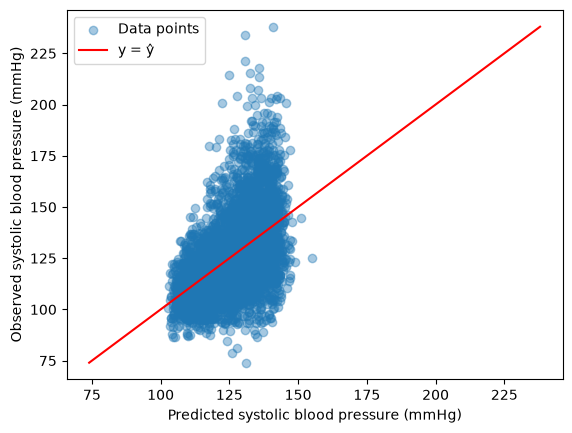

In [4]:
import matplotlib.pyplot as plt

y_hat = model.fitted
fig, ax = plt.subplots()
ax.scatter(y_hat, Y, alpha=0.4, label='Data points')
lims = [min(Y.min(), y_hat.min()), max(Y.max(), y_hat.max())]
ax.plot(lims, lims, color='red', label='y = ŷ')
ax.set_xlabel('Predicted systolic blood pressure (mmHg)')
ax.set_ylabel('Observed systolic blood pressure (mmHg)')
ax.legend()
plt.show()

The cloud is centred on the 45° line, but its vertical spread is clearly larger for high predicted values. This is a first hint that the dispersion of the observations around the fitted values is **not constant**, which motivates the residual analysis of Section 4.

## 3. Inference on the parameters and goodness of fit

### 3.1 Coefficients and standard errors

Estimated coefficients (same order as above):

In [5]:
print(model.beta)

[39.68942184  0.51346566  0.39673984  0.34276231  0.55698777  1.72496351]


Classical standard errors, $\widehat{\text{se}}(\hat\beta_j) = \sqrt{\hat\sigma^2\,[(X'X)^{-1}]_{jj}}$. These are valid **only under homoskedasticity**, which is checked in the following sections.

In [ ]:
sd_er = sd_errors(model)
print(sd_er)

[12.3813416   0.01322699  0.0331038   0.08807658  0.64506883  0.48874813]


### 3.2 $t$-tests on the coefficients

For each coefficient we test $H_0: \beta_j = 0$ against $H_1: \beta_j \neq 0$ (two-sided, 5% level) with $t_j = \hat\beta_j / \widehat{\text{se}}(\hat\beta_j)$.

The cell prints a tuple of three arrays, in the order intercept, `age`, `BMI`, `sodium`, `smoker`, `gender`:
1. the $t$-statistics;
2. the two-sided $p$-values (a printed `0.0` means a value below floating-point precision);
3. a Boolean flag that is `True` when $H_0$ is **not** rejected.

In [8]:
t_test = T_test(model)
res = t_test.test(Y)
print(res)

(array([ 3.2055833 , 38.81954903, 11.98472371,  3.89163951,  0.8634548 ,
        3.52935057]), array([1.35664575e-03, 0.00000000e+00, 0.00000000e+00, 1.00906593e-04,
       3.87930219e-01, 4.20451864e-04]), array([False, False, False, False,  True, False]))


**Interpretation** (holding the other regressors fixed):

| Parameter | Estimate | Std. error | $t$ | $p$-value | Decision (5%) |
|---|---|---|---|---|---|
| $\beta_0$ (intercept) | 39.689 | 12.381 | 3.206 | 0.0014 | reject $H_0$ |
| $\beta_1$ (age) | 0.513 | 0.013 | 38.820 | $<0.001$ | reject $H_0$ |
| $\beta_2$ (BMI) | 0.397 | 0.033 | 11.985 | $<0.001$ | reject $H_0$ |
| $\beta_3$ (sodium) | 0.343 | 0.088 | 3.892 | $<0.001$ | reject $H_0$ |
| $\beta_4$ (smoker) | 0.557 | 0.645 | 0.863 | 0.388 | do not reject $H_0$ |
| $\beta_5$ (gender) | 1.725 | 0.489 | 3.529 | $<0.001$ | reject $H_0$ |

- One more year of age is associated with an average increase of about 0.51 mmHg in systolic pressure, one more BMI unit with about 0.40 mmHg and one more unit of sodium with about 0.34 mmHg.
- Individuals with `gender` = 1 have, on average, a pressure about 1.7 mmHg higher.
- `smoker` is **not** significant ($p = 0.388$): in this sample there is no evidence of a smoking effect once the other regressors are controlled for.
- `age` is by far the most influential regressor ($t \approx 38.8$).

These $t$-tests rely on the classical standard errors, so their reliability depends on the homoskedasticity assumption tested below.

### 3.3 Goodness of fit

$R^2 = 1 - \text{RSS}/\text{TSS}$ and the adjusted $R^2$, which penalises the number of regressors.

In [7]:
res = model.get_stats()['residuals']
r_sqr = R_squared_real(res, Y)
adj_r_sqr = R_squared(res, Y)

print("R^2", r_sqr)
print("adjusted R^2", adj_r_sqr)

R^2 0.26380836594261436
adjusted R^2 0.2638083659426145


Both measures are about $0.264$: the regressors explain roughly a quarter of the variability of blood pressure. With a large sample and only five regressors, the adjustment for the number of parameters is negligible.

## 4. Residual analysis

Let $\hat\varepsilon_i = y_i - \hat y_i$ denote the OLS residuals. If the errors are homoskedastic, the residuals should show the same spread whatever the value of $\hat y$ or of any regressor. Graphs are only indicative, so the formal tests of Section 5 follow.

### 4.1 Residuals against the fitted values

Left: residuals $\hat\varepsilon$ against $\hat y$. Right: squared residuals $\hat\varepsilon^2$ against $\hat y$; $\hat\varepsilon^2$ is a (noisy) proxy of $\text{Var}(\varepsilon_i)$.

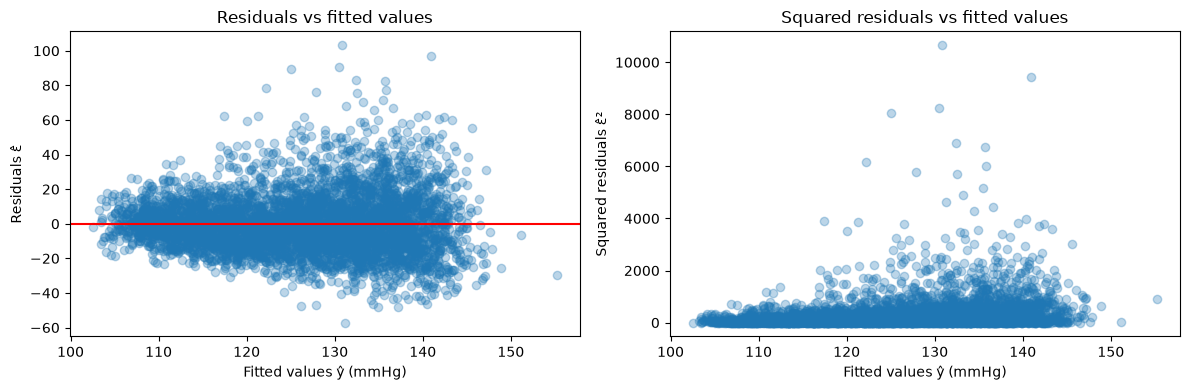

In [5]:
res = model.get_stats()['residuals']
y_hat = model.fitted

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_hat, res, alpha=0.3)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('Fitted values ŷ (mmHg)')
axes[0].set_ylabel('Residuals ε̂')
axes[0].set_title('Residuals vs fitted values')

axes[1].scatter(y_hat, res**2, alpha=0.3)
axes[1].set_xlabel('Fitted values ŷ (mmHg)')
axes[1].set_ylabel('Squared residuals ε̂²')
axes[1].set_title('Squared residuals vs fitted values')

plt.tight_layout()
plt.show()

**Left panel.** The residuals form a *funnel*: they are tightly concentrated around zero for small fitted values and increasingly dispersed as $\hat y$ grows.

**Right panel.** The envelope of the squared residuals rises with $\hat y$, so a straight line fitted through them would have a positive slope. The rise is not perfectly linear: it shows a slight **upward curvature**, i.e. the variance seems to grow faster than linearly in $\hat y$.

Both features are incompatible with a constant error variance.

### 4.2 Residuals against each regressor

To find which regressor drives the pattern, we plot the residuals against each of them. For the continuous variables the orange curves are $\pm 2$ standard deviations of the residuals, computed in ten quantile-based bins (`binned_std`); for the binary variables we show box plots of the residuals in the two groups.

C:\Users\pezzo\AppData\Local\Temp\ipykernel_11984\80101035.py:4: RuntimeWarning: Mean of empty slice
  centers = np.array([x[idx == b].mean() for b in range(bins)])
c:\Users\pezzo\OneDrive\Desktop\università\magistrale\Regression and time series models\regression\venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\pezzo\OneDrive\Desktop\università\magistrale\Regression and time series models\regression\venv\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\pezzo\OneDrive\Desktop\università\magistrale\Regression and time series models\regression\venv\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\pezzo\OneDrive\Desktop\università\magistrale\Regression and t

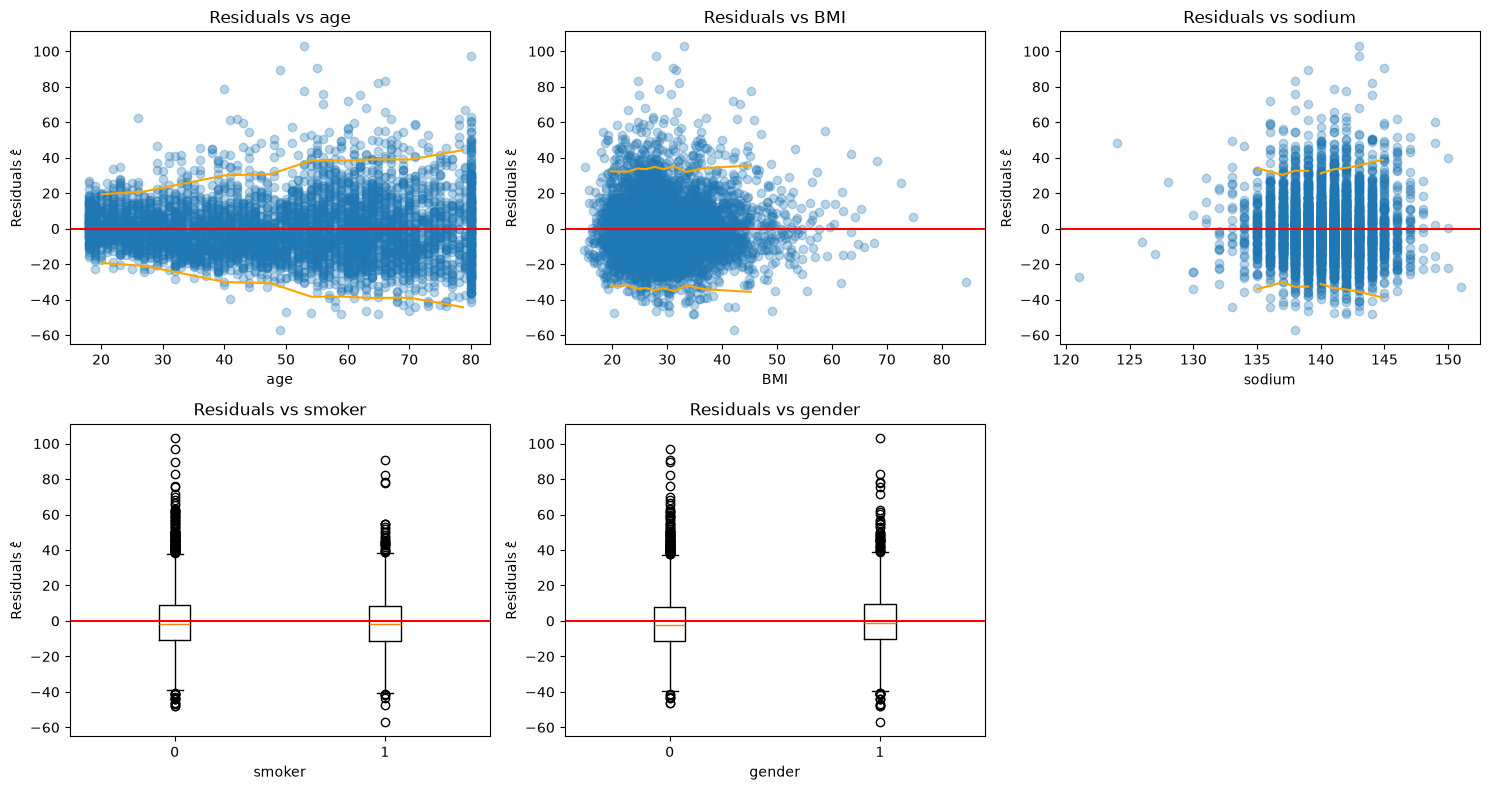

In [6]:
def binned_std(x, r, bins=10):
    edges = np.quantile(x, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.digitize(x, edges[1:-1]), 0, bins - 1)
    centers = np.array([x[idx == b].mean() for b in range(bins)])
    stds = np.array([r[idx == b].std() for b in range(bins)])
    return centers, stds


continuous = ['age', 'BMI', 'sodium']
dummies = ['smoker', 'gender']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()


for ax, name in zip(axes[:3], continuous):
    x = X[name].to_numpy()
    ax.scatter(x, res, alpha=0.3)
    centers, stds = binned_std(x, res)
    ax.plot(centers, 2 * stds, color='orange')
    ax.plot(centers, -2 * stds, color='orange')
    ax.axhline(0, color='red')
    ax.set_xlabel(name)
    ax.set_ylabel('Residuals ε̂')
    ax.set_title(f'Residuals vs {name}')


for ax, name in zip(axes[3:5], dummies):
    x = X[name].to_numpy()
    ax.boxplot([res[x == 0], res[x == 1]])
    ax.set_xticklabels(['0', '1'])
    ax.axhline(0, color='red')
    ax.set_xlabel(name)
    ax.set_ylabel('Residuals ε̂')
    ax.set_title(f'Residuals vs {name}')

axes[5].axis('off')
plt.tight_layout()
plt.show()

> The `RuntimeWarning`s come from `binned_std`: some quantile bins can be empty (for example for the discrete variable `sodium`), so their mean and standard deviation are undefined (NaN) and are not drawn.

**Findings.**
- The $\pm 2\sigma$ bands widen markedly with `age` (from roughly $\pm 20$ at age 20 to more than $\pm 40$ above age 55), whereas they are essentially flat with respect to `BMI` and `sodium`.
- The box plots for `smoker` and `gender` show comparable spreads in the two groups, so no relevant variance imbalance is attached to the dummy variables.
- Since `age` has the largest coefficient, it dominates the fitted values; it is therefore the main driver of the growth of the variance along $\hat y$.

The graphical diagnostics **point to heteroskedasticity**: $\text{Var}(\varepsilon_i \mid X) = \sigma_i^2$ appears to depend on the regressors, mainly on `age`. We now formalise this with two tests.

## 5. Formal tests

We use two tests with complementary roles:

- **RESET** checks the specification of the **mean** function. It is *not* a test for heteroskedasticity, but it is needed first: if the mean were misspecified, patterns in the residuals could come from the mean rather than from the variance, and the White test would be hard to interpret.
- **White** test for **heteroskedasticity**: it detects dependence of the error variance on the regressors, including convex (quadratic) patterns like the one in Section 4.

### 5.1 RESET test: is the linear mean function adequate?

Ramsey's RESET test augments the model with powers of the fitted values. With the square of $\hat y$:

$$y_i = X_i'\boldsymbol\beta + \delta_2\,\hat y_i^{2} + \varepsilon_i,$$

and tests $H_0: \delta_2 = 0$ (correct linear specification of the mean) with the usual $F$-statistic comparing the restricted and the augmented model:

$$F = \frac{(\text{RSS}_R - \text{RSS}_U)/q}{\text{RSS}_U/(n-k-q)} \sim F_{q,\,n-k-q} \quad \text{under } H_0,$$

where $q$ is the number of added terms ($q = 1$ here), $k$ the number of parameters of the original model, and $\text{RSS}_R$, $\text{RSS}_U$ the residual sums of squares of the restricted and augmented models. The argument `2` below is the power of $\hat y$ added.

The cell prints the $F$-statistic, the $p$-value and a Boolean that is `True` when $H_0$ is **not** rejected (the printed label `H0 accettata?` means "is $H_0$ accepted?").

In [17]:
w_test = Reset_test(model)
test_res = w_test.test(2)
print(f"F-test: {test_res[0]}\np-value: {test_res[1]}\nH0 accettata?: {test_res[2]}")

F-test: 0.2605652698800958
p-value: 0.6097553419164075
H0 accettata?: True


**Result.** $F = 0.26$, $p = 0.61$: $H_0$ is **not rejected** at the 5% level. There is no evidence of a neglected non-linearity in the regressors, so the linear specification of the mean is supported. Consequently, the curvature seen in the squared residuals (Section 4.1) does not come from the mean function but is a feature of the **variance**.

### 5.2 White test for heteroskedasticity

The squared residuals in Section 4.1 grow faster than linearly in $\hat y$. The White test is well suited to this situation: its auxiliary regression includes, besides the regressors, their squares and cross-products, so it can capture quadratic (convex) variance patterns. The hypotheses are

$$H_0: \text{Var}(\varepsilon_i \mid X) = \sigma^2 \;\;(\text{homoskedasticity}), \qquad H_1: \text{the variance depends on } x_j,\; x_j^2 \text{ or } x_j x_m .$$

**Standard auxiliary regression.** With $k$ regressors $x_1, \dots, x_k$, the squared OLS residuals are regressed on all the regressors, their squares and their pairwise products:

$$\hat\varepsilon_i^2 = \gamma_0 + \sum_{j=1}^{k} \gamma_j x_{ij} + \sum_{j=1}^{k} \gamma_{k+j}\, x_{ij}^2 + \sum_{j<m} \gamma_{jm}\, x_{ij}x_{im} + \eta_i ,$$

which has $q = 2k + k(k-1)/2$ slope coefficients. In our model ($k = 5$: `age`, `BMI`, `sodium`, $D^{\text{smoker}}$, $D^{\text{gender}}$) it reads

$$\begin{aligned}
\hat\varepsilon^2 = {} & \omega + \gamma_1\,\text{age} + \gamma_2\,\text{BMI} + \gamma_3\,\text{sodium} + \gamma_4\,D^{\text{smoker}} + \gamma_5\,D^{\text{gender}} \\
& + \gamma_6\,\text{age}^2 + \gamma_7\,\text{BMI}^2 + \gamma_8\,\text{sodium}^2 + \gamma_9\,(D^{\text{smoker}})^2 + \gamma_{10}\,(D^{\text{gender}})^2 \\
& + \gamma_{11}\,\text{age}\cdot\text{BMI} + \gamma_{12}\,\text{age}\cdot\text{sodium} + \gamma_{13}\,\text{age}\cdot D^{\text{smoker}} + \gamma_{14}\,\text{age}\cdot D^{\text{gender}} \\
& + \gamma_{15}\,\text{BMI}\cdot\text{sodium} + \gamma_{16}\,\text{BMI}\cdot D^{\text{smoker}} + \gamma_{17}\,\text{BMI}\cdot D^{\text{gender}} \\
& + \gamma_{18}\,\text{sodium}\cdot D^{\text{smoker}} + \gamma_{19}\,\text{sodium}\cdot D^{\text{gender}} + \gamma_{20}\,D^{\text{smoker}}D^{\text{gender}} + \eta .
\end{aligned}$$

**Why a literal implementation fails.** A binary variable takes only the values 0 and 1, hence

$$(D^{\text{smoker}})^2 = D^{\text{smoker}}, \qquad (D^{\text{gender}})^2 = D^{\text{gender}}.$$

The columns of $\gamma_9$ and $\gamma_{10}$ in the auxiliary design matrix $X_U$ are therefore exact copies of those of $\gamma_4$ and $\gamma_5$. $X_U$ does not have full column rank, $X_U'X_U$ is singular and the auxiliary OLS estimator $(X_U'X_U)^{-1}X_U'\hat{\boldsymbol\varepsilon}^2$ cannot be computed.

**Modified auxiliary regression.** To restore full rank we remove the redundant columns: the squares of the dummy variables and any other column that would duplicate an existing one. The squares of the continuous variables are kept, since they are the terms that capture the curvature seen in Section 4.1:

$$\hat\varepsilon^2 = \omega + \gamma_1\,\text{age} + \gamma_2\,\text{BMI} + \gamma_3\,\text{sodium} + \gamma_4\,D^{\text{smoker}} + \gamma_5\,D^{\text{gender}} + \gamma_6\,\text{age}^2 + \gamma_7\,\text{BMI}^2 + \gamma_8\,\text{sodium}^2 + \sum_{r=9}^{q} \gamma_r\, z_r + \eta ,$$

where $z_9, \dots, z_q$ are the retained cross-products, renumbered consecutively after the removal, and $q$ is now the number of non-redundant regressors (excluding the constant).

**Test statistic.** $H_0: \gamma_1 = \dots = \gamma_q = 0$ (all slope coefficients of the auxiliary regression vanish), tested with

$$F = \frac{R^2_{\text{aux}}/q}{\left(1 - R^2_{\text{aux}}\right)/(n-q-1)} \sim F_{q,\,n-q-1} \quad \text{under } H_0 .$$

The cell prints the $F$-statistic, the $p$-value and a Boolean that is `True` when $H_0$ is **not** rejected.

In [7]:
w_test = White_test_for_dummyes(model)
test_res = w_test.test()
print(f"F-test: {test_res[0]}\np-value: {test_res[1]}\nH0 accettata?: {test_res[2]}")

F-test: 17.380399900638157
p-value: 0.0
H0 accettata?: False


**Result.** $F = 17.38$ and $p \approx 0$ (below machine precision): $H_0$ is **rejected** at any usual significance level. Homoskedasticity is strongly rejected, in agreement with the graphical evidence of Section 4.

## 6. Conclusions

- The linear model explains about 26.4% of the variance of systolic pressure. `age`, `BMI`, `sodium` and `gender` are significant; `smoker` is not ($p = 0.388$). The estimates were cross-checked against JASP (Enter method), which reproduces coefficients, standard errors, $t$-statistics, $p$-values and $R^2$.
- The residual plots show a funnel-shaped pattern, with a slight upward curvature of $\hat\varepsilon^2$ against $\hat y$, driven mainly by `age`.
- The RESET test ($F = 0.26$, $p = 0.61$) does not reject the linear specification of the mean, so the pattern is attributed to the variance and not to a neglected non-linearity.
- The White test, in the modified version that excludes the squares of the dummies (which would make $X_U'X_U$ singular), rejects homoskedasticity ($F = 17.38$, $p \approx 0$).

**Consequences.** Since the mean function is correctly specified, the OLS estimates $\hat{\boldsymbol\beta}$ remain unbiased and consistent. What breaks down is the inference: the classical standard errors, and hence the $t$-tests of Section 3.2, are not reliable. They should be replaced by heteroskedasticity-robust (White/HC) standard errors, or the model should be re-estimated by weighted least squares with weights modelling the variance as a function of `age`.